# Probabilistic FDM — Poisson方程式 (Matérnカーネル)

PDE: $-u''(x) = f(x) = \sin(2\pi x)$, $\quad u(0)=u(1)=0$

真の解: $u(x) = \frac{1}{(2\pi)^2}\sin(2\pi x)$

観測モデル: $y = H u + \varepsilon$, $\quad H = -\Delta_h$ (負の有限差分ラプラシアン)

観測ノイズ: $\varepsilon \sim \mathcal{N}(0,\, C h^{2\tau} I_{M,N})$, $\quad C, \ell, \sigma_f$ を周辺尤度で推定

In [81]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Printf
using Statistics

## 1. Matérnカーネル

In [82]:
function matern_kernel(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    if r == 0
        return σf^2
    end
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_matern(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ, σf=σf) for x1 in X1, x2 in X2]
end

kernel_matrix_matern (generic function with 1 method)

## 2. 問題設定・観測行列 H・log周辺尤度

In [83]:
# --------------------------------------------------------
# 問題設定: -u'' = f, u(0)=u(1)=0
# f(x) = sin(2πx), u_exact(x) = sin(2πx)/(2π)^2
# --------------------------------------------------------
u_exact(x) = sin(2π * x) / (2π)^2
f_func(x)  = sin(2π * x)

# --------------------------------------------------------
# 観測行列 H = -Δ_h (負の有限差分ラプラシアン)
# 行順: [bdry_0, int_1, ..., int_{N-1}, bdry_N]
# 内点行: (-u_{i-1} + 2u_i - u_{i+1}) / h^2  = -Δ_h u_i ≈ -u''_i = f_i
# → Hu = y = (0, f(x_1), ..., f(x_{N-1}), 0) と直接対応
# --------------------------------------------------------
function observation_matrix(n_total, dt)
    n_int = n_total - 2
    H = zeros(n_total, n_total)
    H[1, 1]     = 1.0
    H[end, end] = 1.0
    for i in 1:n_int
        H[i+1, i]   = -1.0 / dt^2   # -Δ_h
        H[i+1, i+1] =  2.0 / dt^2
        H[i+1, i+2] = -1.0 / dt^2
    end
    return H
end

# 観測ベクトル: y = (u(0), f(x_1), ..., f(x_{N-1}), u(1))
make_y_train(x_all) = vcat(0.0, f_func.(x_all[2:end-1]), 0.0)

# --------------------------------------------------------
# log周辺尤度: 観測ノイズ Σ = C * h^{2τ} * diag(0,1,...,1,0)
# --------------------------------------------------------
function log_marginal_matern(
    X_train, y; H, dt, ν, ℓ, σf, C, τ, jitter=1e-10
)
    n_total   = length(X_train)
    noise_var = C * dt^(2τ)
    Σ_diag    = vcat([0.0], fill(noise_var, n_total - 2), [0.0])
    #Σ_diag    = fill(noise_var, n_total)
    Σ         = Diagonal(Σ_diag)

    K     = kernel_matrix_matern(X_train, X_train; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ #+ jitter * I

    L       = cholesky(Hermitian(K_obs)).L
    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))

    return -0.5 * (y' * α) - 0.5 * logdetK - 0.5 * length(y) * log(2π)
end

log_marginal_matern (generic function with 1 method)

In [84]:
function solve_fdm(dt)
    x_all = collect(0.0:dt:18.0)
    x_int = x_all[2:end-1]
    n_int = length(x_int)
    A = SymTridiagonal(fill(2.0/dt^2, n_int), fill(-1.0/dt^2, n_int-1))
    f_vec = f_func.(x_int)
    u_int = ldiv!(factorize(A), copy(f_vec))
    return x_all, vcat(0.0, u_int, 0.0)
end

dt = 0.4
x_fdm, u_fdm = solve_fdm(dt)
err = maximum(abs.(u_fdm .- u_exact.(x_fdm)))
println("h=$(dt):  max|u_fdm - u_exact| = $(round(err, sigdigits=4))")



σf_rms  = sqrt(mean(u_fdm.^2))

h=0.4:  max|u_fdm - u_exact| = 0.01797


0.030928558807569867

## 3. ハイパーパラメータ選択 (ℓ, σf, C をグリッドサーチ)

In [92]:
ν_fixed = 1.5
τ_fixed = 2
#dt_list = [0.4, 0.3, 0.2,  0.05]
dt_list = [0.2]

# ℓ, σf, C をグリッドサーチ
# σf のスケールは H の内点行が 1/h^2 オーダーなので
# HKH' ~ σf^2/h^4 が観測値のスケール(~1)に合うよう
# σf ~ h^2 付近を中心にグリッドを張る
#ℓ_grid = 10 .^ range(-1, 1, length=10)   # 0.1 〜 100
ℓ_grid = 10 .^ range(-1, 1, length=10)
#σf_grid = 10 .^ range(-2, 0, length=10)   # 0.01 〜 10
σf_grid = [σf_rms]
C_grid = 10 .^ range(-3, 2, length=10)  
#ℓ_grid =  [10 .^ (-1.6)]
#σf_grid = [10 .^ (-1.6)]   # 0.01 〜 100

best_params = Dict()

for dt in dt_list
    x_all   = collect(0.0:dt:18.0)
    n_total = length(x_all)
    H       = observation_matrix(n_total, dt)
    y_train = make_y_train(x_all)

    # σf のグリッドを dt に応じてスケール
    # HKH' 対角 ~ σf^2/h^4 → σf ~ h^2 が自然なスケール
    #σf_center = dt^2
    #σf_grid = σf_center .* 10 .^ range(-2, 3, length=15)

    scores = fill(-Inf, length(ℓ_grid), length(σf_grid), length(C_grid))

    for (i, ℓ) in enumerate(ℓ_grid)
        for (j, σf) in enumerate(σf_grid)
            for (k, C) in enumerate(C_grid)
                try
                    scores[i,j,k] = log_marginal_matern(
                        x_all, y_train;
                        H=H, dt=dt, ν=ν_fixed,
                        ℓ=ℓ, σf=σf, C=C, τ=τ_fixed
                    )
                catch
                    scores[i,j,k] = -Inf
                end
            end
        end
    end

    best_idx = argmax(scores)
    bI       = CartesianIndices(scores)[best_idx]
    best_ℓ   = ℓ_grid[bI[1]]
    best_σf  = σf_grid[bI[2]]
    best_C   = C_grid[bI[3]]
    best_params[dt] = (best_ℓ, best_σf, best_C)

    #snr = best_σf^2 / dt^4 / (best_C * dt^(2*τ_fixed))
    println("dt=$(dt): ℓ=$(round(best_ℓ,sigdigits=3)), ",
            "σf=$(round(best_σf,sigdigits=3)), ",
            "C=$(round(best_C,sigdigits=3)), ",
            "loglik=$(round(scores[best_idx],sigdigits=5)), ",
#            "SNR=$(round(snr,sigdigits=3))"
            )
end


dt=0.2: ℓ=0.464, σf=0.0309, C=0.001, loglik=-52.685, 


## 4. 事後分布の計算と4パネル図

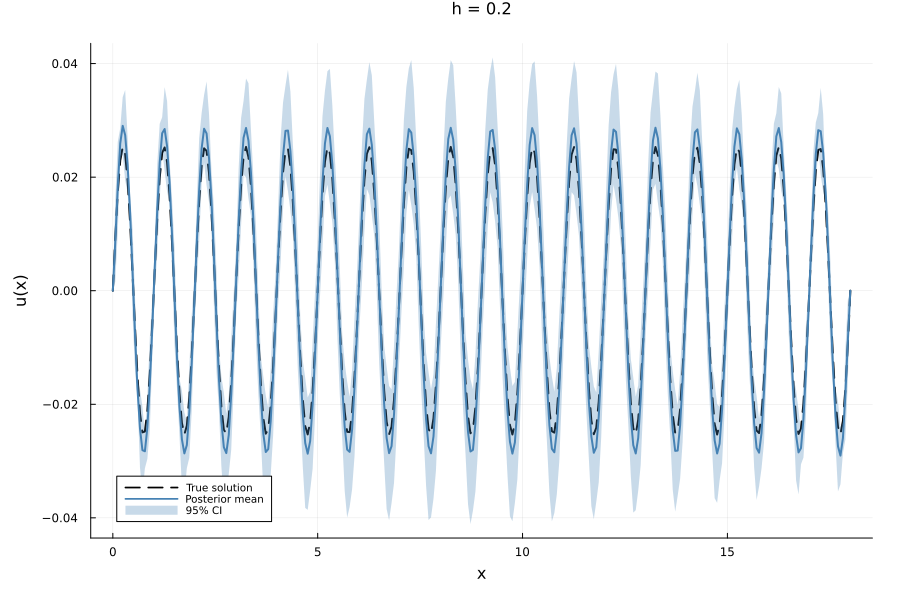

Saved: poisson_matern_4panels.png


In [93]:
function run_pfdm(dt; ν, ℓ, σf, C, τ, n_test=300)
    x_all   = collect(0.0:dt:18.0)
    n_total = length(x_all)
    H       = observation_matrix(n_total, dt)
    y_train = make_y_train(x_all)

    noise_var = C * dt^(2τ)
    Σ_diag    = vcat([0.0], fill(noise_var, n_total - 2), [0.0])
    Σ         = Diagonal(Σ_diag)

    K     = kernel_matrix_matern(x_all, x_all; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ #+ 1e-10 * I

    X_test = collect(range(0.0, 18.0, length=n_test))
    # 事後平均: μ = k(X_test, x_all) * H' * (HKH'+Σ)^{-1} * y
    Ks     = kernel_matrix_matern(X_test, x_all; ν=ν, ℓ=ℓ, σf=σf) * H'
    Kss    = kernel_matrix_matern(X_test, X_test; ν=ν, ℓ=ℓ, σf=σf)

    K_chol   = cholesky(Hermitian(K_obs))
    μ_post   = Ks * (K_chol \ y_train)
    Σ_post   = Kss - Ks * (K_chol \ Ks')
    std_post = sqrt.(max.(diag(Σ_post), 0.0))

    return X_test, μ_post, std_post, u_exact.(X_test)
end

plots_list = []

for dt in dt_list
    best_ℓ, best_σf, best_C = best_params[dt]
    X_test, μ, σ, u_true = run_pfdm(
        dt; ν=ν_fixed, ℓ=best_ℓ, σf=best_σf, C=best_C, τ=τ_fixed
    )

    p = plot(
        X_test, u_true;
        label="True solution",
        lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(x)",
        title="h = $(dt)",
        titlefontsize=11, legendfontsize=7,
    )
    plot!(p, X_test, μ;
        label="Posterior mean", lw=2, color=:steelblue
    )
    plot!(p, X_test, μ .+ 1.96 .* σ;
        fillrange = μ .- 1.96 .* σ,
        fillalpha = 0.3, linealpha = 0,
        label = "95% CI", color = :steelblue
    )
    push!(plots_list, p)
end

fig = plot(
    plots_list...;
    layout = (2, 2),
    size   = (900, 600),
    margin = 5Plots.mm,
)
display(fig)
savefig(fig, "poisson_matern_4panels.png")
println("Saved: poisson_matern_4panels.png")

## 通常のFDM（比較用）

三重対角行列を直接解く標準的な有限差分法。各 h でのFDM解と最大誤差を求め，Probabilistic FDM と同じパネルに重ねてプロット。

## プロット（Probabilistic FDM ＋ 通常FDM 重ね描き）

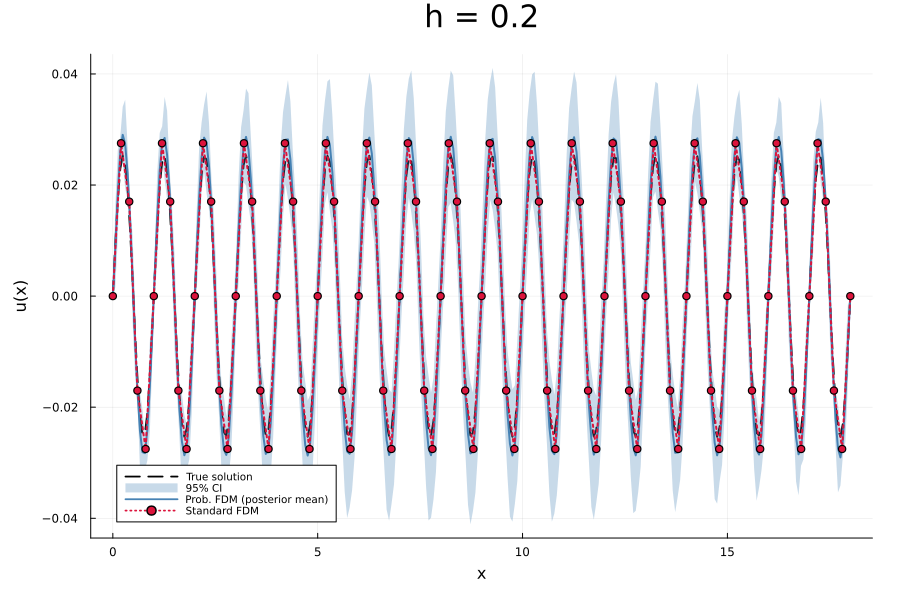

Saved: poisson_comparison_4panels.png


In [94]:
plots_list2 = []

for dt in dt_list
    best_ℓ, best_σf, best_C = best_params[dt]
    X_test, μ, σ, u_true = run_pfdm(
        dt; ν=ν_fixed, ℓ=best_ℓ, σf=best_σf, C=best_C, τ=τ_fixed
    )
    x_fdm, u_fdm = solve_fdm(dt)

    p = plot(
        X_test, u_true;
        label="True solution",
        lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(x)",
        title="h = $(dt)",
        titlefontsize=21, legendfontsize=7,
    )
    plot!(p, X_test, μ .+ 1.96 .* σ;
        fillrange = μ .- 1.96 .* σ,
        fillalpha = 0.3, linealpha = 0,
        label = "95% CI", color = :steelblue
    )
    plot!(p, X_test, μ;
        label="Prob. FDM (posterior mean)", lw=2, color=:steelblue
    )
    plot!(p, x_fdm, u_fdm;
        label="Standard FDM", lw=2, ls=:dot, color=:crimson,
        markershape=:circle, markersize=4
    )
    push!(plots_list2, p)
end

fig2 = plot(
    plots_list2...;
    layout = (2, 2),
    size   = (900, 600),
    margin = 5Plots.mm,
)
display(fig2)
savefig(fig2, "poisson_comparison_4panels.png")
println("Saved: poisson_comparison_4panels.png")




In [121]:
# ============================================================
# σf を FDM 解から推定して，ℓ vs C の lml 表を表示
# ============================================================

dt = 0.4
x_all   = collect(0.0:dt:18.0)
n_total = length(x_all)
H       = observation_matrix(n_total, dt)
y_train = make_y_train(x_all)




# σf_rms で固定して ℓ vs C の表
σf_fixed = σf_rms
σf_fixed = 0.3
#ℓ_grid_table = 10.0 .^ range(0, 3, length=6)
ℓ_grid_table = [0.000001, 0.0001, 0.2, 0.4, 0.5, 1.0, 3.0, 5.0, 15.0, 50, 100, 1000000]
#C_grid_table = vcat([0.0], 10.0 .^ range(-4, 2, length=8))
#C_grid_table =10.0 .^ range(-8, 8, length=10)
C_grid_table =[0.1, 0.5, 1.0, 2.0, 5.0]

println("\n=== lml table (σf=$(round(σf_fixed,sigdigits=3)) fixed, h=$(dt)) ===")
@printf("%-12s", "ℓ \\ C")
for C in C_grid_table
    if C == 0.0
        @printf("%-11s", "0")
    else
        @printf("%-11s", round(C, sigdigits=2))
    end
end
println()
println("-"^(12 + 11*length(C_grid_table)))

best_lml = -Inf; best_l = ℓ_grid_table[1]; best_C = C_grid_table[1]

for ℓ in ℓ_grid_table
    @printf("%-12s", round(ℓ, sigdigits=2))
    for C in C_grid_table
        lml = try
            log_marginal_matern(x_all, y_train;
                H=H, dt=dt, ν=ν_fixed,
                ℓ=ℓ, σf=σf_fixed, C=C, τ=τ_fixed)
        catch
            NaN
        end
        @printf("%-11s", isnan(lml) ? "NaN" : round(lml, digits=1))
        if !isnan(lml) && lml > best_lml
            best_lml = lml; best_l = ℓ; best_C = C
        end
    end
    println()
end
println("-"^(12 + 11*length(C_grid_table)))
println("Best: ℓ=$(round(best_l,sigdigits=3)), C=$(round(best_C,sigdigits=3)), lml=$(round(best_lml,digits=2))")



=== lml table (σf=0.3 fixed, h=0.4) ===
ℓ \ C       0.1        0.5        1.0        2.0        5.0        
-------------------------------------------------------------------
1.0e-6      -74.1      -76.3      -77.6      -79.2      -81.9      
0.0001      -74.1      -76.3      -77.6      -79.2      -81.9      
0.2         -73.5      -75.5      -76.8      -78.3      -80.8      
0.4         -67.5      -69.3      -70.3      -71.7      -73.9      
0.5         -63.4      -65.1      -66.1      -67.4      -69.6      
1.0         -46.4      -47.8      -48.8      -50.0      -52.3      
3.0         -144.9     -127.8     -111.7     -90.6      -63.5      
5.0         -606.0     -373.2     -251.0     -152.6     -76.8      
15.0        -3532.8    -788.1     -390.1     -192.2     -82.2      
50.0        -4277.3    -821.2     -397.7     -193.4     -81.8      
100.0       -4298.7    -821.5     -397.4     -192.9     -81.2      
1.0e6       -4292.7    -812.5     -388.3     -183.8     -72.2      
-------

In [115]:
# ============================================================
# lml の各項 t1, t2 を別々に表示して原因を特定
# t1 = -0.5 * y^T M^{-1} y  (データフィット項)
# t2 = -0.5 * log|M|        (複雑度ペナルティ項)
# ============================================================

dt = 0.4
x_all   = collect(0.0:dt:18.0)
n_total = length(x_all)
H       = observation_matrix(n_total, dt)
y_train = make_y_train(x_all)

_, u_fdm_04 = solve_fdm(dt)
σf_fixed = sqrt(mean(u_fdm_04.^2))
println("σf_fixed (rms) = $(round(σf_fixed, sigdigits=3))")

#ℓ_grid = 10.0 .^ range(-4, 2, length=5)
ℓ_grid = [0.01, 0.5]
C_grid = vcat([0.0], 10.0 .^ range(-4, 2, length=8))

#σf_fixed = σf_rms
σf_fixed = 1.0
#ℓ_grid_table = 10.0 .^ range(0, 3, length=6)
ℓ_grid_table = [0.4, 0.5, 1.0, 3.0, 5.0, 15.0]
#C_grid_table = vcat([0.0], 10.0 .^ range(-4, 2, length=8))
C_grid_table =10.0 .^ range(-8, 8, length=10)


function compute_t1_t2(ℓ, C; σf=σf_fixed, τ=τ_fixed, ν=ν_fixed)
    n = length(x_all)
    K = kernel_matrix_matern(x_all, x_all; ν=ν, ℓ=ℓ, σf=σf)
    noise_diag = vcat([0.0], fill(C*dt^(2τ), n-2), [0.0])
    M = Symmetric(H * K * H' + Diagonal(noise_diag) + 1e-10*I)
    L = cholesky(M).L
    α = L' \ (L \ y_train)
    t1 = -0.5 * dot(y_train, α)
    t2 = -sum(log.(diag(L)))
    return t1, t2
end

for (name, get_val) in [
    ("t1 = -0.5 * y^T M^{-1} y", (l,C) -> compute_t1_t2(l,C)[1]),
    ("t2 = -0.5 * log|M|",        (l,C) -> compute_t1_t2(l,C)[2]),
    ("lml = t1 + t2 - const",     (l,C) -> sum(compute_t1_t2(l,C)) - 0.5*length(x_all)*log(2π)),
]
    println("\n=== $(name) ===")
    @printf("%-10s", "ℓ \\ C")
    for C in C_grid
        @printf("%9s", C == 0.0 ? "0" : "$(round(C,sigdigits=2))")
    end
    println()
    println("-"^(10 + 9*length(C_grid)))
    for ℓ in ℓ_grid
        @printf("%-10s", round(ℓ, sigdigits=2))
        for C in C_grid
            v = try get_val(ℓ, C) catch; NaN end
            @printf("%9s", isnan(v) ? "NaN" : round(v, digits=1))
        end
        println()
    end
end


σf_fixed (rms) = 0.0309

=== t1 = -0.5 * y^T M^{-1} y ===
ℓ \ C             0   0.0001  0.00072   0.0052    0.037     0.27      1.9     14.0    100.0
-------------------------------------------------------------------------------------------
0.01           -0.0     -0.0     -0.0     -0.0     -0.0     -0.0     -0.0     -0.0     -0.0
0.5            -0.1     -0.1     -0.1     -0.1     -0.1     -0.1     -0.1     -0.1     -0.1

=== t2 = -0.5 * log|M| ===
ℓ \ C             0   0.0001  0.00072   0.0052    0.037     0.27      1.9     14.0    100.0
-------------------------------------------------------------------------------------------
0.01          -84.4    -84.4    -84.5    -84.5    -84.8    -85.8    -87.6    -91.0    -96.9
0.5           -73.7    -73.7    -73.7    -73.7    -73.9    -74.5    -75.8    -78.4    -83.3

=== lml = t1 + t2 - const ===
ℓ \ C             0   0.0001  0.00072   0.0052    0.037     0.27      1.9     14.0    100.0
-------------------------------------------------------

In [116]:
# ============================================================
# M の固有値を数値的に確認
# λ_min(M) が小さいと t2 が人工的に大きくなる
# ============================================================

println("=== λ_min(M) と λ_max(M) ===")
@printf("%-10s %10s %10s %12s %12s %12s\n",
    "ℓ", "C", "C*h^(2τ)", "λ_min(M)", "λ_max(M)", "condition")
println("-"^68)

for ℓ in [0.0001, 0.01, 0.1, 1.0], C in [0.0, 0.001, 1.0, 100.0]
    K = kernel_matrix_matern(x_all, x_all; ν=ν_fixed, ℓ=ℓ, σf=σf_fixed)
    noise_diag = vcat([0.0], fill(C*dt^(2τ_fixed), n_total-2), [0.0])
    M = Symmetric(H * K * H' + Diagonal(noise_diag) + 1e-10*I)
    ev = eigvals(M)
    λ_min = minimum(ev)
    λ_max = maximum(ev)
    cond  = λ_max / λ_min
    @printf("%-10s %10s %10s %12s %12s %12s\n",
        round(ℓ,sigdigits=2),
        round(C,sigdigits=2),
        round(C*dt^(2τ_fixed),sigdigits=2),
        round(λ_min,sigdigits=3),
        round(λ_max,sigdigits=3),
        round(cond,sigdigits=3))
end



=== λ_min(M) と λ_max(M) ===
ℓ                   C   C*h^(2τ)     λ_min(M)     λ_max(M)    condition
--------------------------------------------------------------------
0.0001            0.0        0.0     0.000912        623.0     684000.0
0.0001          0.001     2.6e-5     0.000937        623.0     666000.0
0.0001            1.0      0.026        0.026        624.0      24000.0
0.0001          100.0        2.6        0.496        626.0       1260.0
0.01              0.0        0.0     0.000912        623.0     684000.0
0.01            0.001     2.6e-5     0.000937        623.0     666000.0
0.01              1.0      0.026        0.026        624.0      24000.0
0.01            100.0        2.6        0.496        626.0       1260.0
0.1               0.0        0.0     0.000926        614.0     663000.0
0.1             0.001     2.6e-5     0.000951        614.0     645000.0
0.1               1.0      0.026        0.026        614.0      23600.0
0.1             100.0        2.6       

In [117]:
println()
println("=== λ_min(HKH^T) (ノイズなし) ===")
println("C*h^(2τ) がこれより大きくなって初めて正則化が効く")
println()
@printf("%-10s %20s %12s\n", "ℓ", "λ_min(HKH^T)", "-0.5*log(λ_min)")
println("-"^44)
for ℓ in [0.01, 0.1, 1.0, 10.0]
    K = kernel_matrix_matern(x_all, x_all; ν=ν_fixed, ℓ=ℓ, σf=σf_fixed)
    HKHt = H * K * H'
    ev = eigvals(Symmetric(HKHt + 1e-10*I))
    λ_min = minimum(ev)
    t2_contribution = -0.5 * log(λ_min)
    @printf("%-10s %20s %12s\n",
        round(ℓ,sigdigits=2),
        round(λ_min,sigdigits=3),
        round(t2_contribution,sigdigits=3))
end

println()
println("→ C*h^(2τ) = $(round(1.0*dt^(2τ_fixed), sigdigits=3)) (C=1の場合)")
println("→ C*h^(2τ) = $(round(0.001*dt^(2τ_fixed), sigdigits=3)) (C=0.001の場合)")



=== λ_min(HKH^T) (ノイズなし) ===
C*h^(2τ) がこれより大きくなって初めて正則化が効く

ℓ                  λ_min(HKH^T) -0.5*log(λ_min)
--------------------------------------------
0.01                   0.000912          3.5
0.1                    0.000926         3.49
1.0                     0.00516         2.63
10.0                     0.0078         2.43

→ C*h^(2τ) = 0.0256 (C=1の場合)
→ C*h^(2τ) = 2.56e-5 (C=0.001の場合)


=== C=7.7 での各 ℓ の UQ 比較 ===
パラメータ                        MAP err    max std    std/err        lml
------------------------------------------------------------------------
ℓ=0.01, C≈0 (端)                 0.017968   0.000132      0.007    -126.73
ℓ=0.2, C=7.7                     0.017954   0.346268     19.286    -131.17
ℓ=0.4=h, C=7.7                   0.018059   0.429778     23.798    -124.42
ℓ=0.5, C=7.7 (prev best)         0.018194   0.465597     25.590    -119.74
ℓ=1.0, C=7.7                     0.019970   0.593763     29.733     -97.38
calibrated ref (ℓ=0.1,C=1)       0.017966   0.244517     13.610    -129.15

FDM L∞ error = 0.017968

Saved: poisson_localmax_C7.png

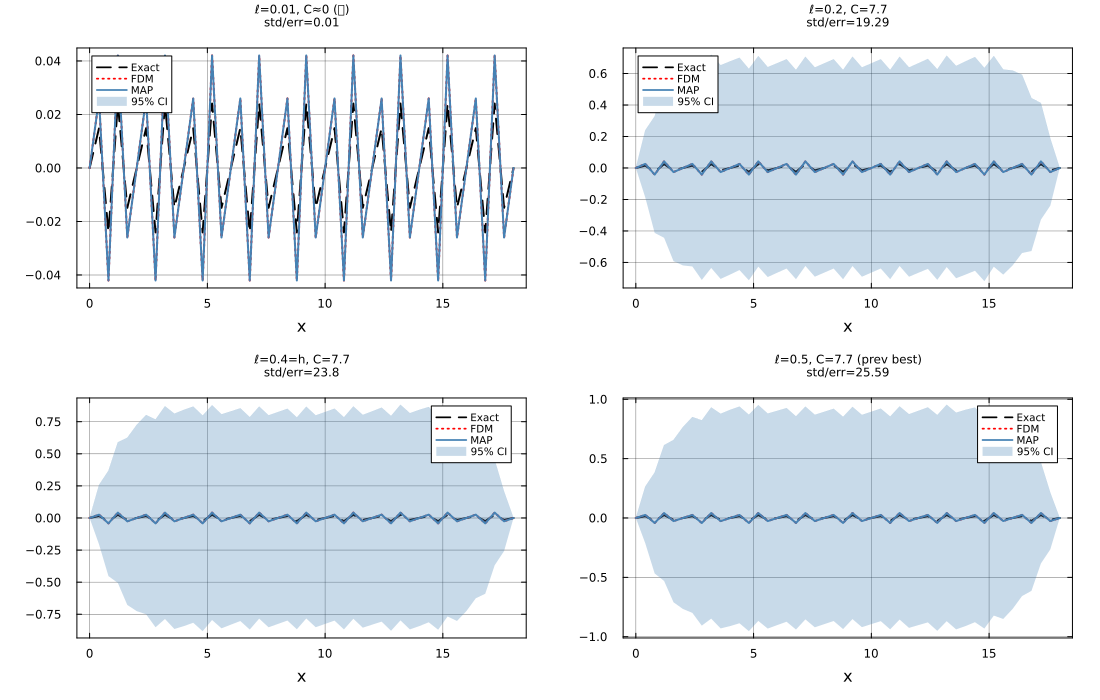

GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471
GKS: glyph missing from current font: 31471


In [118]:
# ============================================================
# C ≈ 7.7 の interior local max での UQ 確認
# 各 ℓ での C=7.7 付近の結果を比較
# ============================================================

dt     = 0.4
x_all  = collect(0.0:dt:18.0)
n_total = length(x_all)
H      = observation_matrix(n_total, dt)
y_train = make_y_train(x_all)
u_star  = u_exact.(x_all)
_, u_fdm_v = solve_fdm(dt)
err_fdm = maximum(abs.(u_fdm_v - u_star))

function run_posterior(ℓ, C, σf)
    K = kernel_matrix_matern(x_all, x_all; ν=ν_fixed, ℓ=ℓ, σf=σf)
    noise_diag = vcat([0.0], fill(C*dt^(2τ_fixed), n_total-2), [0.0])
    M = Symmetric(H * K * H' + Diagonal(noise_diag) + 1e-10*I)
    L = cholesky(M).L
    α = L' \ (L \ y_train)
    mu  = K * H' * α
    V   = L \ (H * K)
    std = sqrt.(max.(diag(K) - vec(sum(V.^2, dims=1)), 0.0))
    lml = -0.5*dot(y_train, α) - sum(log.(diag(L))) - 0.5*n_total*log(2π)
    return mu, std, lml
end

println("=== C=7.7 での各 ℓ の UQ 比較 ===")
println(@sprintf("%-30s %10s %10s %10s %10s",
    "パラメータ", "MAP err", "max std", "std/err", "lml"))
println("-"^72)

candidates = [
    (1e-8, 1e-8, σf_fixed, "ℓ=0.01, C≈0 (端)"),
    (0.2,  7.7,  σf_fixed, "ℓ=0.2, C=7.7"),
    (0.4,  7.7,  σf_fixed, "ℓ=0.4=h, C=7.7"),
    (0.501,7.7,  σf_fixed, "ℓ=0.5, C=7.7 (prev best)"),
    (1.0,  7.7,  σf_fixed, "ℓ=1.0, C=7.7"),
    (0.1,  1.0,  σf_fixed, "calibrated ref (ℓ=0.1,C=1)"),
]

plots_list = []
for (ℓ, C, σf, label) in candidates
    mu, std, lml = run_posterior(ℓ, C, σf)
    err_map = maximum(abs.(mu - u_star))
    max_std = maximum(std)
    println(@sprintf("%-30s %10.6f %10.6f %10.3f %10.2f",
        label, err_map, max_std, max_std/err_map, lml))

    if label != "calibrated ref (ℓ=0.1,C=1)" && label != "ℓ=1.0, C=7.7"
        pp = plot(x_all, u_star;
            label="Exact", lw=2, ls=:dash, color=:black,
            xlabel="x", title="$(label)\nstd/err=$(round(max_std/err_map,digits=2))",
            titlefontsize=8, legendfontsize=7,
            grid=true, gridalpha=0.3, framestyle=:box)
        plot!(pp, x_all, u_fdm_v; label="FDM", lw=2, ls=:dot, color=:red)
        plot!(pp, x_all, mu; label="MAP", lw=2, color=:steelblue)
        plot!(pp, x_all, mu .+ 1.96.*std;
            lw=0, fillalpha=0, label=false, color=:steelblue)
        plot!(pp, x_all, mu .- 1.96.*std;
            lw=0, fillrange=mu .+ 1.96.*std,
            fillalpha=0.3, linealpha=0, label="95% CI", color=:steelblue)
        push!(plots_list, pp)
    end
end
println()
println("FDM L∞ error = $(round(err_fdm, digits=6))")

fig = plot(plots_list...;
    layout=(2,2), size=(1100,700), margin=5*Plots.mm)
display(fig)
savefig(fig, "poisson_localmax_C7.png")
println("\nSaved: poisson_localmax_C7.png")

